# F1 Analytics


## 1. Dataset Selection

### Dataset Name
**Formula One (F1) Historical Race and Session Results Dataset, 2019–2024**

### Source
The dataset was obtained from the **Jolpica-F1 database**, an open-source project providing historical Formula One data. The data was downloaded as CSV files from the project's database dumps and is being analysed locally using Python and Pandas.

Source: https://github.com/jolpica/jolpica-f1

### Why I Chose It
I chose this dataset because of my interest in Formula One, particularly the engineering and aerodynamic developments that influence car performance. The sport provides an opportunity to explore how changes in technical regulations may be associated with differences in race outcomes.

The dataset contains information about drivers, teams, race results, starting grid positions, points and individual sessions. This makes it suitable for data cleaning, manipulation, statistical analysis and visualisation using Python.

I selected the period from 2019 to 2024 to compare three seasons before the major 2022 aerodynamic regulation changes with the three seasons that followed. This provides a consistent time window for investigating patterns across the two periods.

### Potential Question to Explore
**Did the relationship between qualifying position and race finishing position change after the 2022 Formula One regulations?**

To investigate this question, I will compare qualifying and finishing positions across the 2019–2021 and 2022–2024 periods. I will use statistical analysis and visualisations to examine whether qualifying performance became more or less strongly associated with race results following the regulatory changes.

The analysis will identify patterns in the data rather than assume that regulation changes alone caused any differences observed.



## 2. Initital Data Exploration

In [64]:
import pandas as pd
from fastf1.ergast import Ergast
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

In [18]:
# check the files are loaded correctly
data_folder = Path("f1-csv")
csv_files = list(data_folder.glob("*.csv"))

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

Number of CSV files: 18
formula_one_baseteam.csv
formula_one_championshipadjustment.csv
formula_one_championshipsystem.csv
formula_one_circuit.csv
formula_one_driver.csv
formula_one_driverchampionship.csv
formula_one_lap.csv
formula_one_penalty.csv
formula_one_pitstop.csv
formula_one_pointsystem.csv
formula_one_round.csv
formula_one_roundentry.csv
formula_one_season.csv
formula_one_session.csv
formula_one_sessionentry.csv
formula_one_team.csv
formula_one_teamchampionship.csv
formula_one_teamdriver.csv


In [19]:
# Load the tables I need into Pandas
baseteam = pd.read_csv(data_folder / "formula_one_baseteam.csv")
sessionentry = pd.read_csv(data_folder / "formula_one_sessionentry.csv")
session = pd.read_csv(data_folder / "formula_one_session.csv")
rounds = pd.read_csv(data_folder / "formula_one_round.csv")
seasons = pd.read_csv(data_folder / "formula_one_season.csv")
drivers = pd.read_csv(data_folder / "formula_one_driver.csv")
teams = pd.read_csv(data_folder / "formula_one_team.csv")

In [32]:
# Inspect first rows
print("SESSION ENTRY")
sessionentry.head()

print("SESSION")
session.head()

print("ROUND")
rounds.head()

print("SEASON")
seasons.head()

# Here, I noticed that the seasons start from the inaugural season in 1950

SESSION ENTRY
SESSION
ROUND
SEASON


,id,api_id,championship_system_id,wikipedia,year
0,1,season_oPqQEC4b,1,https://en.wikipedia.org/wiki/1950_Formula_One...,1950
1,2,season_nH07GTj5,1,https://en.wikipedia.org/wiki/1951_Formula_One...,1951
2,3,season_AkHDeRX4,1,https://en.wikipedia.org/wiki/1952_Formula_One...,1952
3,4,season_E63rvZZO,1,https://en.wikipedia.org/wiki/1953_Formula_One...,1953
4,5,season_B36NWfA1,2,https://en.wikipedia.org/wiki/1954_Formula_One...,1954


In [26]:
# Work out column names, data types and no. of rows and columns
for name, df in {
    "sessionentry": sessionentry,
    "session": session,
    "rounds": rounds,
    "seasons": seasons,
    "drivers": drivers,
    "teams": teams
}.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.dtypes)


--- sessionentry ---
Shape: (51685, 16)
Columns: ['id', 'api_id', 'detail', 'driver_of_the_day_percentage', 'driver_of_the_day_winner', 'fastest_lap_rank', 'grid', 'is_classified', 'is_eligible_for_points', 'laps_completed', 'points', 'position', 'round_entry_id', 'session_id', 'status', 'time']
id                                int64
api_id                           object
detail                           object
driver_of_the_day_percentage    float64
driver_of_the_day_winner        float64
fastest_lap_rank                float64
grid                            float64
is_classified                    object
is_eligible_for_points           object
laps_completed                  float64
points                          float64
position                        float64
round_entry_id                    int64
session_id                        int64
status                          float64
time                             object
dtype: object

--- session ---
Shape: (5130, 13)
Columns: ['id

In [22]:
for name, df in {
    "sessionentry": sessionentry,
    "session": session,
    "rounds": rounds,
    "seasons": seasons,
    "drivers": drivers,
    "teams": teams
}.items():
    print(f"\n{name}:")
    print(df.columns.tolist())
    


sessionentry:
['id', 'api_id', 'detail', 'driver_of_the_day_percentage', 'driver_of_the_day_winner', 'fastest_lap_rank', 'grid', 'is_classified', 'is_eligible_for_points', 'laps_completed', 'points', 'position', 'round_entry_id', 'session_id', 'status', 'time']

session:
['id', 'api_id', 'completed_distance', 'completed_laps', 'has_time_data', 'is_cancelled', 'number', 'point_system_id', 'round_id', 'scheduled_laps', 'timestamp', 'timezone', 'type']

rounds:
['id', 'api_id', 'circuit_id', 'date', 'is_cancelled', 'name', 'number', 'race_number', 'season_id', 'wikipedia']

seasons:
['id', 'api_id', 'championship_system_id', 'wikipedia', 'year']

drivers:
['id', 'abbreviation', 'api_id', 'country_code', 'date_of_birth', 'forename', 'nationality', 'permanent_car_number', 'reference', 'surname', 'wikipedia']

teams:
['id', 'api_id', 'base_team_id', 'country_code', 'name', 'nationality', 'primary_color', 'reference', 'wikipedia']


## 3. Data Cleaning

My data is split into multiple CSVs so inspection of the tables to work out primary and foreign key is needed

In [31]:
roundentry = pd.read_csv(data_folder / "formula_one_roundentry.csv")

print("Shape:", roundentry.shape)
print("Columns:", roundentry.columns.tolist())
roundentry.head()

Shape: (27663, 5)
Columns: ['id', 'api_id', 'car_number', 'round_id', 'team_driver_id']


,id,api_id,car_number,round_id,team_driver_id
0,1,roundentry_FUFWqiHA,2.0,1,1
1,2,roundentry_X2Oso05J,3.0,1,2
2,3,roundentry_wjjINPdb,4.0,1,3
3,4,roundentry_kg7fbLfc,14.0,1,4
4,5,roundentry_LAN7L55t,15.0,1,5


In [30]:
teamdriver = pd.read_csv(data_folder / "formula_one_teamdriver.csv")

print("Shape:", teamdriver.shape)
print("Columns:", teamdriver.columns.tolist())
teamdriver.head()

Shape: (3630, 6)
Columns: ['id', 'api_id', 'driver_id', 'role', 'season_id', 'team_id']


,id,api_id,driver_id,role,season_id,team_id
0,1,teamdriver_LSox06Od,1,NaN,1,1
1,2,teamdriver_bLowFOCJ,2,NaN,1,1
2,3,teamdriver_d8PF1G74,3,NaN,1,1
3,4,teamdriver_DuMzxcI2,4,NaN,1,5
4,5,teamdriver_0BTCGA9I,5,NaN,1,5


In [33]:
# Selection of the six seasons in scope
seasons_2019_2024 = seasons[
    seasons["year"].between(2019, 2024)
].copy()

# Select the rounds that match up to the years
rounds_2019_2024 = rounds[
    rounds["season_id"].isin(seasons_2019_2024["id"])
].copy()

# Select sessions belonging to those rounds
sessions_2019_2024 = session[
    session["round_id"].isin(rounds_2019_2024["id"])
].copy()

# Select the entries belonging to those sessions
entries_2019_2024 = sessionentry[
    sessionentry["session_id"].isin(sessions_2019_2024["id"])
].copy()

print("Seasons:", seasons_2019_2024["year"].min(),
      "to", seasons_2019_2024["year"].max())
print("Number of seasons:", seasons_2019_2024["year"].nunique())
print("Rounds:", len(rounds_2019_2024))
print("Sessions:", len(sessions_2019_2024))
print("Session entries:", len(entries_2019_2024))

Seasons: 2019 to 2024
Number of seasons: 6
Rounds: 128
Sessions: 920
Session entries: 9129


In [35]:
# Duplicate check:
print("Duplicate session entry IDs:",
      entries_2019_2024["id"].duplicated().sum())

print("Duplicate session IDs:",
      sessions_2019_2024["id"].duplicated().sum())

print("Duplicate round IDs:",
      rounds_2019_2024["id"].duplicated().sum())

print("Duplicate season IDs:",
      seasons_2019_2024["id"].duplicated().sum())

Duplicate session entry IDs: 0
Duplicate session IDs: 0
Duplicate round IDs: 0
Duplicate season IDs: 0


### Duplicate Checks

I checked the primary ID columns in the session entries, sessions, rounds and seasons tables for duplicate values. All four tables contained zero duplicate IDs.

This suggests that the IDs can be used to identify individual records in these tables. Further checks will be carried out after merging to ensure that each driver has the expected number of entries per session and that the joins have not created duplicate records.

In [40]:
# Inspection of relationship tables
roundentry.head()

,id,api_id,car_number,round_id,team_driver_id
0,1,roundentry_FUFWqiHA,2.0,1,1
1,2,roundentry_X2Oso05J,3.0,1,2
2,3,roundentry_wjjINPdb,4.0,1,3
3,4,roundentry_kg7fbLfc,14.0,1,4
4,5,roundentry_LAN7L55t,15.0,1,5


In [38]:
teamdriver.head()

,id,api_id,driver_id,role,season_id,team_id
0,1,teamdriver_LSox06Od,1,NaN,1,1
1,2,teamdriver_bLowFOCJ,2,NaN,1,1
2,3,teamdriver_d8PF1G74,3,NaN,1,1
3,4,teamdriver_DuMzxcI2,4,NaN,1,5
4,5,teamdriver_0BTCGA9I,5,NaN,1,5


In [41]:
roundentry.columns.tolist()

['id', 'api_id', 'car_number', 'round_id', 'team_driver_id']

In [42]:
teamdriver.columns.tolist()

['id', 'api_id', 'driver_id', 'role', 'season_id', 'team_id']

In [43]:
print("Driver columns:")
print(drivers.columns.tolist())

print("\nTeam columns:")
print(teams.columns.tolist())

print("\nSession types in 2019–2024:")
print(sessions_2019_2024["type"].value_counts(dropna=False))

Driver columns:
['id', 'abbreviation', 'api_id', 'country_code', 'date_of_birth', 'forename', 'nationality', 'permanent_car_number', 'reference', 'surname', 'wikipedia']

Team columns:
['id', 'api_id', 'base_team_id', 'country_code', 'name', 'nationality', 'primary_color', 'reference', 'wikipedia']

Session types in 2019–2024:
type
R      128
Q1     128
Q2     128
Q3     128
FP1    128
FP2    116
FP3    110
SR      18
SQ1     12
SQ2     12
SQ3     12
Name: count, dtype: int64


In [44]:
# Making a new DataFrame and merging all the tables

# Add season and race information to each session
session_info = sessions_2019_2024[
    ["id", "type", "round_id"]
].rename(columns={"id": "session_id"})

session_info = session_info.merge(
    rounds_2019_2024[["id", "name", "date", "season_id"]],
    left_on="round_id",
    right_on="id"
).drop(columns="id")

session_info = session_info.merge(
    seasons_2019_2024[["id", "year"]],
    left_on="season_id",
    right_on="id"
).drop(columns="id")


# Add session information to the results
f1_results = entries_2019_2024.merge(
    session_info,
    on="session_id",
    how="left"
)


# merge each result to its race entry
f1_results = f1_results.merge(
    roundentry[["id", "team_driver_id", "car_number"]].rename(
        columns={"id": "round_entry_id"}
    ),
    on="round_entry_id",
    how="left"
)


# merge each race entry to its driver and constructor IDs
f1_results = f1_results.merge(
    teamdriver[["id", "driver_id", "team_id"]].rename(
        columns={"id": "team_driver_id"}
    ),
    on="team_driver_id",
    how="left"
)


# Add drivers
f1_results = f1_results.merge(
    drivers[["id", "forename", "surname"]].rename(
        columns={"id": "driver_id"}
    ),
    on="driver_id",
    how="left"
)


# Add constructors
f1_results = f1_results.merge(
    teams[["id", "name"]].rename(
        columns={"id": "team_id", "name": "team_name"}
    ),
    on="team_id",
    how="left"
)

f1_results.head()

,id,api_id,detail,driver_of_the_day_percentage,driver_of_the_day_winner,fastest_lap_rank,grid,is_classified,is_eligible_for_points,laps_completed,...,date,season_id,year,team_driver_id,car_number,driver_id,team_id,forename,surname,team_name
0,38474,sessionentry_EeURiWah,Finished,NaN,NaN,1.0,2.0,t,t,58.0,...,2019-03-17,70,2019,3418,77.0,820,48,Valtteri,Bottas,Mercedes
1,38475,sessionentry_1jFQI4PW,NaN,NaN,NaN,NaN,NaN,NaN,t,NaN,...,2019-03-17,70,2019,3418,77.0,820,48,Valtteri,Bottas,Mercedes
2,38476,sessionentry_W61tGDAk,NaN,NaN,NaN,NaN,NaN,NaN,t,NaN,...,2019-03-17,70,2019,3418,77.0,820,48,Valtteri,Bottas,Mercedes
3,38477,sessionentry_PpDz0yOl,NaN,NaN,NaN,NaN,NaN,NaN,t,NaN,...,2019-03-17,70,2019,3418,77.0,820,48,Valtteri,Bottas,Mercedes
4,38478,sessionentry_xuvP3yxG,Finished,NaN,NaN,2.0,1.0,t,t,58.0,...,2019-03-17,70,2019,3419,44.0,795,48,Lewis,Hamilton,Mercedes


In [45]:
print("Rows in combined dataset:", len(f1_results))

print("\nMissing driver names:")
print(f1_results["forename"].isna().sum())

print("\nMissing constructor names:")
print(f1_results["team_name"].isna().sum())

print("\nSession types:")
print(f1_results["type"].value_counts())

Rows in combined dataset: 9129

Missing driver names:
0

Missing constructor names:
0

Session types:
type
R      2559
Q1     2556
Q2     1904
Q3     1255
SR      360
SQ1     220
SQ2     165
SQ3     110
Name: count, dtype: int64


In [46]:
# Check for how the dataset records qualifying positions

qualifying_check = f1_results[
    (f1_results["year"] == 2019) &
    (f1_results["type"].isin(["Q1", "Q2", "Q3"]))
]

qualifying_check[
    ["name", "type", "forename", "surname", "position", "grid"]
].head(20)

,name,type,forename,surname,position,grid
1,Australian Grand Prix,Q1,Valtteri,Bottas,2.0,NaN
2,Australian Grand Prix,Q2,Valtteri,Bottas,2.0,NaN
3,Australian Grand Prix,Q3,Valtteri,Bottas,2.0,NaN
5,Australian Grand Prix,Q1,Lewis,Hamilton,1.0,NaN
6,Australian Grand Prix,Q2,Lewis,Hamilton,1.0,NaN
7,Australian Grand Prix,Q3,Lewis,Hamilton,1.0,NaN
9,Australian Grand Prix,Q1,Max,Verstappen,4.0,NaN
10,Australian Grand Prix,Q2,Max,Verstappen,4.0,NaN
11,Australian Grand Prix,Q3,Max,Verstappen,4.0,NaN
13,Australian Grand Prix,Q1,Sebastian,Vettel,3.0,NaN


In [47]:
qualifying_check[
    qualifying_check["name"] == "Australian Grand Prix"
][["type", "forename", "surname", "position", "grid"]].sort_values(
    ["type", "position"]
)

,type,forename,surname,position,grid
5,Q1,Lewis,Hamilton,1.0,NaN
1,Q1,Valtteri,Bottas,2.0,NaN
13,Q1,Sebastian,Vettel,3.0,NaN
9,Q1,Max,Verstappen,4.0,NaN
17,Q1,Charles,Leclerc,5.0,NaN
57,Q1,Romain,Grosjean,6.0,NaN
21,Q1,Kevin,Magnussen,7.0,NaN
39,Q1,Lando,Norris,8.0,NaN
28,Q1,Kimi,Räikkönen,9.0,NaN
43,Q1,Sergio,Pérez,10.0,NaN


This means that the dataset only records the driver's position in the qualifiying session and not the final qualifiying position in for the overall field.

The dataset contains the grid column already whcich records the driver's starting position in the race, which can act as a measure of how a driver qualified (it does however include penalites, which would make it differ from actualy qualifying postions)

In [49]:
# Race-results dataframe
# Keep only Grand Prix race results
race_results = f1_results[
    f1_results["type"] == "R"
].copy()

# Keep the columns relevant to our analysis
race_results = race_results[
    [
        "year",
        "name",
        "date",
        "forename",
        "surname",
        "team_name",
        "grid",
        "position",
        "is_classified",
        "laps_completed",
        "status"
    ]
]

# Create a full driver name
race_results["driver"] = (
    race_results["forename"] + " " + race_results["surname"]
)

# Add the regulation era
race_results["era"] = race_results["year"].apply(
    lambda year: "2019–2021" if year <= 2021 else "2022–2024"
)

race_results.head()

,year,name,date,forename,surname,team_name,grid,position,is_classified,laps_completed,status,driver,era
0,2019,Australian Grand Prix,2019-03-17,Valtteri,Bottas,Mercedes,2.0,1.0,t,58.0,0.0,Valtteri Bottas,2019–2021
4,2019,Australian Grand Prix,2019-03-17,Lewis,Hamilton,Mercedes,1.0,2.0,t,58.0,0.0,Lewis Hamilton,2019–2021
8,2019,Australian Grand Prix,2019-03-17,Max,Verstappen,Red Bull,4.0,3.0,t,58.0,0.0,Max Verstappen,2019–2021
12,2019,Australian Grand Prix,2019-03-17,Sebastian,Vettel,Ferrari,3.0,4.0,t,58.0,0.0,Sebastian Vettel,2019–2021
16,2019,Australian Grand Prix,2019-03-17,Charles,Leclerc,Ferrari,5.0,5.0,t,58.0,0.0,Charles Leclerc,2019–2021


In [50]:
print("Total race entries:", len(race_results))

print("\nMissing starting-grid positions:")
print(race_results["grid"].isna().sum())

print("\nMissing finishing positions:")
print(race_results["position"].isna().sum())

print("\nMissing grid or finishing position:")
print(
    race_results[["grid", "position"]]
    .isna()
    .any(axis=1)
    .sum()
)

print("\nRace entries by year:")
print(race_results.groupby("year").size())

Total race entries: 2559

Missing starting-grid positions:
0

Missing finishing positions:
0

Missing grid or finishing position:
0

Race entries by year:
year
2019    420
2020    340
2021    440
2022    440
2023    440
2024    479
dtype: int64


### Race Data Quality Check

After filtering the combined dataset to include only Grand Prix race sessions (`R`), the dataset contained 2,559 driver-race entries covering 2019–2024.

There were no missing values in the starting-grid (`grid`) or finishing-position (`position`) columns. This means all entries have both values available for the planned comparison.

The number of entries varies by season. In particular, 2024 contains 479 entries, compared with 440 in each of 2021, 2022 and 2023. I will investigate this variation to check for duplicate driver-race records before proceeding with the analysis.

In [51]:
# Check for whether a driver appears more than once in the same race

duplicate_races = race_results.duplicated(
    subset=["year", "name", "driver"],
    keep=False
)

print("Potential duplicate driver-race records:",
      duplicate_races.sum())

race_results[duplicate_races].sort_values(
    ["year", "name", "driver"]
).head(20)

Potential duplicate driver-race records: 0


,year,name,date,forename,surname,team_name,grid,position,is_classified,laps_completed,status,driver,era


In [52]:
print(
    race_results.groupby("year")["name"].nunique()
)

year
2019    21
2020    17
2021    22
2022    22
2023    22
2024    24
Name: name, dtype: int64


In [56]:
race_results[race_results["year"] == 2024].groupby("name").size()
# I noticed that 2024 had one less entrant than expected, but this i was due to a did not start

name
Abu Dhabi Grand Prix         20
Australian Grand Prix        19
Austrian Grand Prix          20
Azerbaijan Grand Prix        20
Bahrain Grand Prix           20
Belgian Grand Prix           20
British Grand Prix           20
Canadian Grand Prix          20
Chinese Grand Prix           20
Dutch Grand Prix             20
Emilia Romagna Grand Prix    20
Hungarian Grand Prix         20
Italian Grand Prix           20
Japanese Grand Prix          20
Las Vegas Grand Prix         20
Mexico City Grand Prix       20
Miami Grand Prix             20
Monaco Grand Prix            20
Qatar Grand Prix             20
Saudi Arabian Grand Prix     20
Singapore Grand Prix         20
Spanish Grand Prix           20
São Paulo Grand Prix         20
United States Grand Prix     20
dtype: int64

### Duplicate Checks

I checked for duplicate driver-race records using the season, Grand Prix name and driver name.

The number of Grands Prix varied between seasons, from 17 in 2020 to 24 in 2024. This explains the variation in the number of driver-race entries across the dataset.


## 4. Analytical questions

The 5 main analytical questions I'm asking are:

    1. Did starting position become a better predictor of finishing position after 2022?
    
    2. Which starting positions most often lead to a win or podium?
    
    3. Did drivers gain or lose more positions after 2022?

    4. How are grid position, finishing position, points and laps completed related?

    5. How did constructor performance change across 2019–2024?

### Pre-requisits to analysis

In [57]:
# Creation of derived columns new rules

#Copy of dataframe for analysis
analysis_df = race_results.copy()

# Calculate positions gained
analysis_df["positions_gained"] = (
    analysis_df["grid"] - analysis_df["position"]
)

# Identify the regulation era
analysis_df["era"] = analysis_df["year"].apply(
    lambda year: "2019–2021" if year <= 2021 else "2022–2024"
)

# Check the calculated values
analysis_df[
    ["year", "name", "driver", "grid", "position", "positions_gained"]
].head(10)

,year,name,driver,grid,position,positions_gained
0,2019,Australian Grand Prix,Valtteri Bottas,2.0,1.0,1.0
4,2019,Australian Grand Prix,Lewis Hamilton,1.0,2.0,-1.0
8,2019,Australian Grand Prix,Max Verstappen,4.0,3.0,1.0
12,2019,Australian Grand Prix,Sebastian Vettel,3.0,4.0,-1.0
16,2019,Australian Grand Prix,Charles Leclerc,5.0,5.0,0.0
20,2019,Australian Grand Prix,Kevin Magnussen,7.0,6.0,1.0
24,2019,Australian Grand Prix,Nico Hülkenberg,11.0,7.0,4.0
27,2019,Australian Grand Prix,Kimi Räikkönen,9.0,8.0,1.0
31,2019,Australian Grand Prix,Lance Stroll,16.0,9.0,7.0
33,2019,Australian Grand Prix,Daniil Kvyat,15.0,10.0,5.0


In [59]:
# Calculation of DNFs, as they counnt as unclassified even though they have position
print(analysis_df["status"].value_counts(dropna=False).head(20))
print("\nClassified status values:")
print(analysis_df["is_classified"].value_counts(dropna=False))

status
0.0     1474
1.0      715
11.0     232
10.0     115
30.0      16
20.0       7
Name: count, dtype: int64

Classified status values:
is_classified
t    2243
f     316
Name: count, dtype: int64


In [60]:
# We only want classified data for comparing starting and finishing position
classified_results = analysis_df[
    analysis_df["is_classified"] == "t"
].copy()

print("All race entries:", len(analysis_df))
print("Classified entries:", len(classified_results))

print("\nMissing grid positions:")
print(classified_results["grid"].isna().sum())

print("\nMissing finishing positions:")
print(classified_results["position"].isna().sum())

All race entries: 2559
Classified entries: 2243

Missing grid positions:
0

Missing finishing positions:
0


### 1. Did starting position become a better predictor of finishing position after 2022?

In [61]:
# Calculate correlation for each regulation era
correlations = classified_results.groupby("era").apply(
    lambda group: group["grid"].corr(group["position"]),
    include_groups=False
)

print(correlations)

era
2019–2021    0.672317
2022–2024    0.686062
dtype: float64


In [63]:
# Because the difference is so small, I want to look at the absolute changes from drivers
classified_results["absolute_position_change"] = (
    classified_results["positions_gained"].abs()
)

classified_results.groupby("era")[
    "absolute_position_change"
].agg(["mean", "median", "std", "count"])

,mean,median,std,count
era,,,,
2019–2021,3.115789,2.0,3.309829,1045
2022–2024,3.106845,2.0,3.191510,1198


#### Analysis 1: Relationship Between Starting Grid and Finishing Position

I compared the relationship between starting-grid position and finishing position across two periods: 2019–2021 and 2022–2024.

The correlation increased slightly from 0.6723 before the 2022 regulations to 0.6861 afterwards. However, the mean absolute position change remained almost identical, decreasing from 3.116 to 3.107 positions. The median absolute change was two positions in both periods.

These results suggest that the relationship between starting-grid position and finishing position remained  similar across the two periods. Thisdoes not establish whether the 2022 regulations caused any change, and does not include DNFs which may sway it more

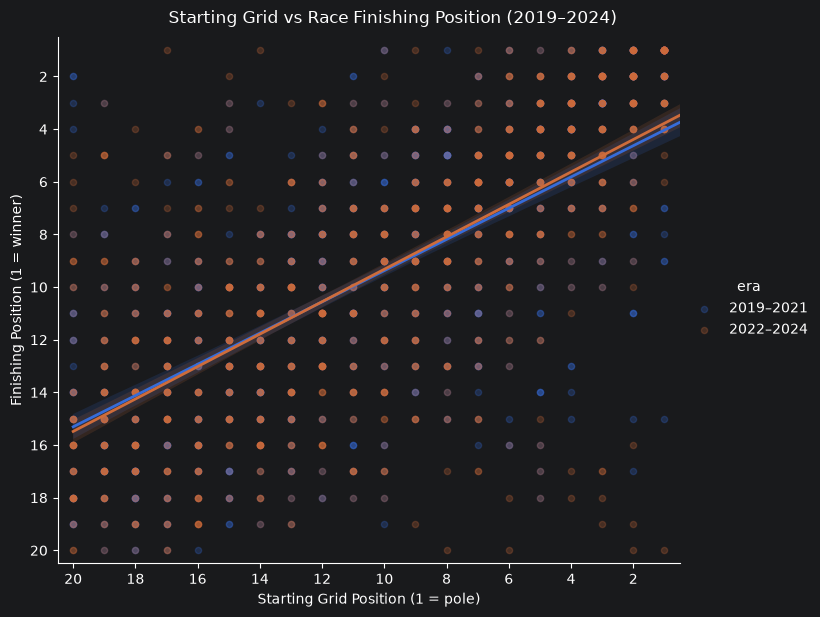

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

g = sns.lmplot(
    data=classified_results,
    x="grid",
    y="position",
    hue="era",
    height=6,
    aspect=1.2,
    scatter_kws={"alpha": 0.25, "s": 20},
    line_kws={"linewidth": 2}
)


for ax in g.axes.flat:
    ax.invert_xaxis()
    ax.invert_yaxis()

    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.yaxis.set_major_locator(MultipleLocator(2))

    ax.set_xlim(20.5, 0.5)
    ax.set_ylim(20.5, 0.5)


g.set_axis_labels(
    "Starting Grid Position (1 = pole)",
    "Finishing Position (1 = winner)"
)

g.figure.suptitle(
    "Starting Grid vs Race Finishing Position (2019–2024)",
    y=1.02
)

plt.show()


### 2: Which starting-grid positions produce the most podium finishes?

I classified each result as either a podium finish (position >4) or not, then calculated the percentage of drivers from each starting postion who finished on a podium

In [82]:
podium_data = classified_results.copy()

# Identify podium finishes
podium_data["podium"] = podium_data["position"].between(1, 3)

# Calculate podium percentage for each grid position and era
podium_rates = (
    podium_data.groupby(["era", "grid"])["podium"]
    .mean()
    .mul(100)
    .reset_index()
)

podium_rates.head()

,era,grid,podium
0,2019–2021,0.0,0.000000
1,2019–2021,1.0,85.714286
2,2019–2021,2.0,75.438596
3,2019–2021,3.0,71.698113
4,2019–2021,4.0,34.545455


In [88]:
# Use only classified race results
podium_data = classified_results.copy()

# Identify podium finishes
podium_data["podium"] = podium_data["position"].between(1, 3)

# Calculate podium percentage by era and starting-grid position
# Podium rate is calculated by the percent of number of podium results by all results from that position
podium_rates = (
    podium_data[podium_data["grid"] >= 1]
    .groupby(["era", "grid"])["podium"]
    .mean()
    .mul(100)
    .reset_index()
    .rename(columns={"podium": "podium_percentage"})
)

podium_rates.head(7)

,era,grid,podium_percentage
0,2019–2021,1.0,85.714286
1,2019–2021,2.0,75.438596
2,2019–2021,3.0,71.698113
3,2019–2021,4.0,34.545455
4,2019–2021,5.0,14.814815
5,2019–2021,6.0,11.320755
6,2019–2021,7.0,7.407407


In [99]:
# Reindex so each era becomes a column
heatmap_data = podium_rates.pivot(
    index="grid",
    columns="era",
    values="podium_percentage"
)


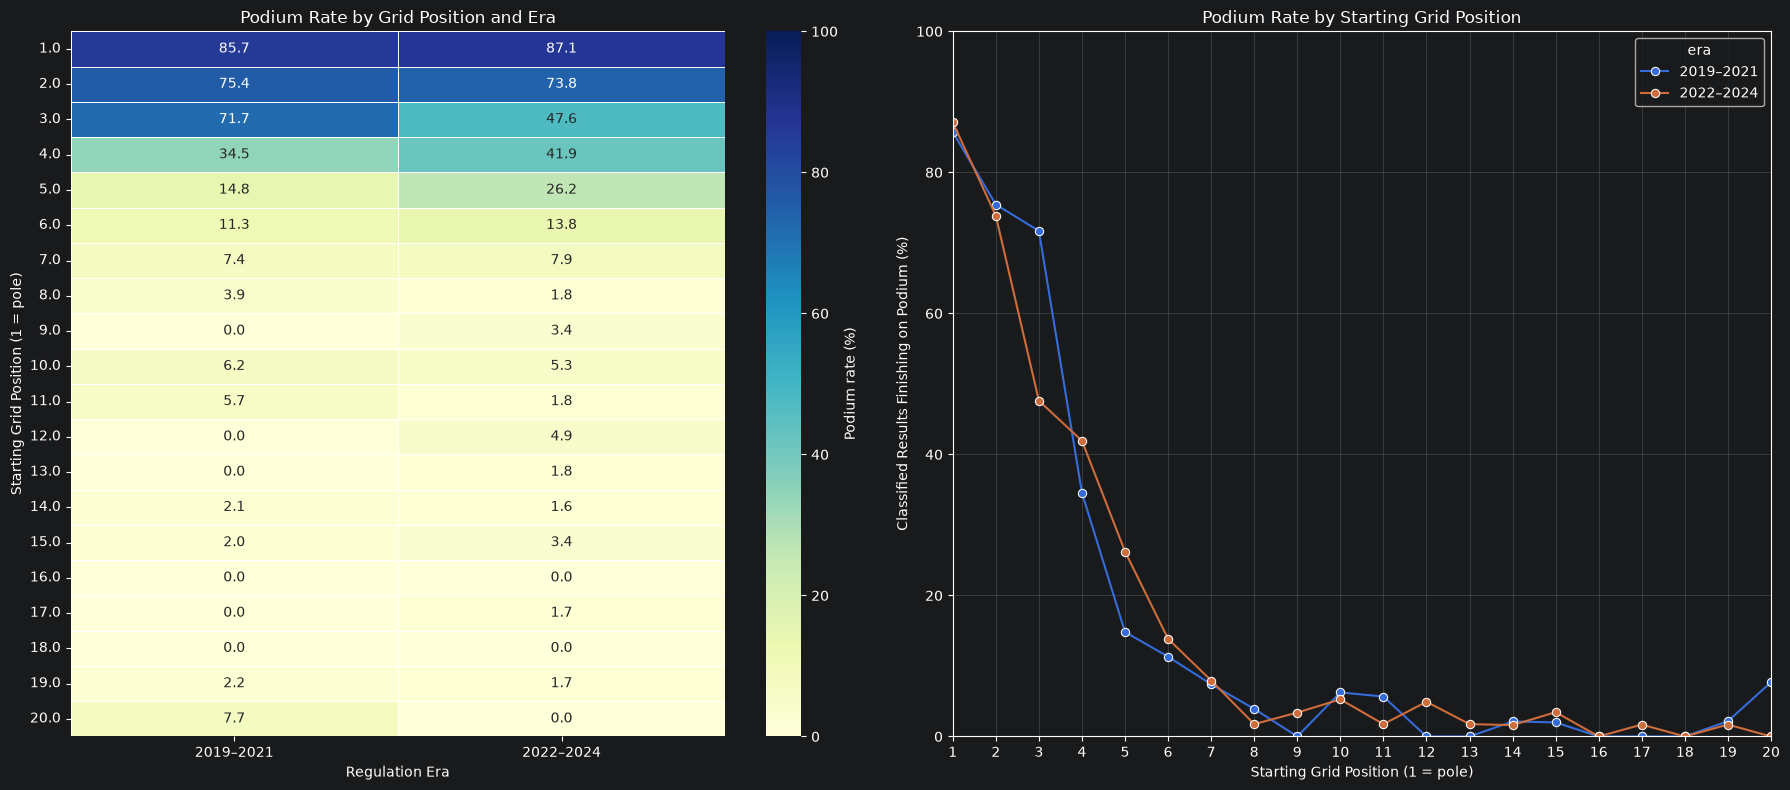

In [104]:
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# LEFT: Heatmap
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Podium rate (%)"},
    ax=axes[0]
)

axes[0].set_title("Podium Rate by Grid Position and Era")
axes[0].set_xlabel("Regulation Era")
axes[0].set_ylabel("Starting Grid Position (1 = pole)")


# RIGHT: Line graph
sns.lineplot(
    data=podium_rates,
    x="grid",
    y="podium_percentage",
    hue="era",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Podium Rate by Starting Grid Position")
axes[1].set_xlabel("Starting Grid Position (1 = pole)")
axes[1].set_ylabel("Classified Results Finishing on Podium (%)")
axes[1].set_xticks(range(1, 21))
axes[1].set_xlim(1, 20)
axes[1].set_ylim(0, 100)
axes[1].grid(alpha=0.3)

plt.tight_layout()


In [98]:
#Calculate the number of classified results behind each percenrage, to help judge reliablity of results at the back of the grid
podium_counts = (
    podium_data[podium_data["grid"] >= 1]
    .groupby(["era", "grid"])
    .agg(
        classified_starts=("podium", "size"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

podium_counts.head(5)

,era,grid,classified_starts,podiums
0,2019–2021,1.0,56,48
1,2019–2021,2.0,57,43
2,2019–2021,3.0,53,38
3,2019–2021,4.0,55,19
4,2019–2021,5.0,54,8


#### Analysis 2: Which Starting-Grid Positions Produce the Most Podium Finishes?

The results show a clear relationship between starting position and podium success. Drivers starting on pole position achieved a podium in **85.7% of classified results in 2019–2021 and 87.1% in 2022–2024**. Second place on the grid also produced high podium rates of 75.4% and 73.8%, respectively. This demonstrates that starting near the front of the grid was strongly associated with achieving a podium in both periods.

However, the results varied between individual positions. The podium rate for drivers starting third fell from 71.7% before the 2022 regulations to 47.6% afterwards, while the rate for drivers starting fifth increased from 14.8% to 26.2%. Despite these differences, podiums remained uncommon for drivers starting further back. For example, the podium rate for grid position 10 was approximately 5–6% in both periods.

Overall, the analysis suggests that **starting near the front of the grid was associated with a substantially higher chance of achieving a podium**, both before and after the 2022 regulations. Although some individual grid positions experienced changes in podium rates, the overall pattern remained similar.

### 3. Did Drivers Gain or Lose More Positions After 2022?

In [106]:
# Summary stats
position_summary = (
    classified_results.groupby("era")["positions_gained"]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)

position_summary

,mean,median,std,count
era,,,,
2019–2021,0.58,1.0,4.51,1045
2022–2024,0.72,1.0,4.40,1198


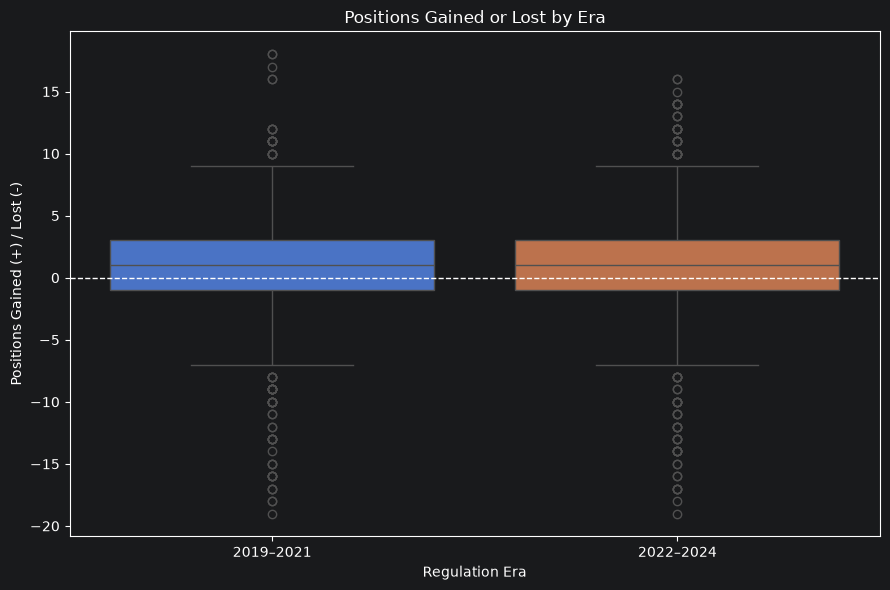

In [114]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=classified_results,
    x="era",
    y="positions_gained",
    hue="era",
    legend=False
)

plt.axhline(0, color="white", linestyle="--", linewidth=1)
plt.title("Positions Gained or Lost by Era")
plt.xlabel("Regulation Era")
plt.ylabel("Positions Gained (+) / Lost (-)")
plt.tight_layout()
plt.show()

#### Analysis 3: Did Drivers Gain or Lose More Positions After 2022?

Positions gained were calculated by subtracting finishing position from starting-grid position, meaning positive values indicate positions gained and negative values indicate positions lost.

The mean number of positions gained **increased from 0.58 in 2019–2021 to 0.72 in 2022–2024.** This represents a small increase of 0.14 positions per classified result. The median remained at one position gained in both periods, suggesting that the typical result was broadly unchanged. The standard deviation also decreased slightly, from 4.51 to 4.40, indicating marginally less variation in position changes in the later period.

The box plot illustrates the distribution of position changes in each era, with individual points beyond the whiskers representing unusually large gains or losses. These results show that **drivers gained slightly more positions on average after 2022**, but the difference was small and the overall pattern remained similar.

Overall, there is little evidence of a substantial change in position gains after the 2022 regulations.

### 4. How are grid position, finishing position, points and laps completed related?

In [115]:
# Select race sessions only
analysis4 = f1_results[f1_results["type"] == "R"].copy()

# Keep the variables needed for this analysis
analysis4 = analysis4[
    [
        "year",
        "name",
        "forename",
        "surname",
        "grid",
        "position",
        "points",
        "laps_completed",
        "is_classified"
    ]
].copy()

# regulation era
analysis4["era"] = analysis4["year"].apply(
    lambda year: "2019–2021" if year <= 2021 else "2022–2024"
)


analysis4.head()

,year,name,forename,surname,grid,position,points,laps_completed,is_classified,era
0,2019,Australian Grand Prix,Valtteri,Bottas,2.0,1.0,26.0,58.0,t,2019–2021
4,2019,Australian Grand Prix,Lewis,Hamilton,1.0,2.0,18.0,58.0,t,2019–2021
8,2019,Australian Grand Prix,Max,Verstappen,4.0,3.0,15.0,58.0,t,2019–2021
12,2019,Australian Grand Prix,Sebastian,Vettel,3.0,4.0,12.0,58.0,t,2019–2021
16,2019,Australian Grand Prix,Charles,Leclerc,5.0,5.0,10.0,58.0,t,2019–2021


In [117]:
# Check data types
print(analysis4[[
    "grid",
    "position",
    "points",
    "laps_completed"
]].dtypes)

# Check missing values
print(analysis4[[
    "grid",
    "position",
    "points",
    "laps_completed"
]].isna().sum())

grid              float64
position          float64
points            float64
laps_completed    float64
dtype: object
grid              0
position          0
points            0
laps_completed    0
dtype: int64


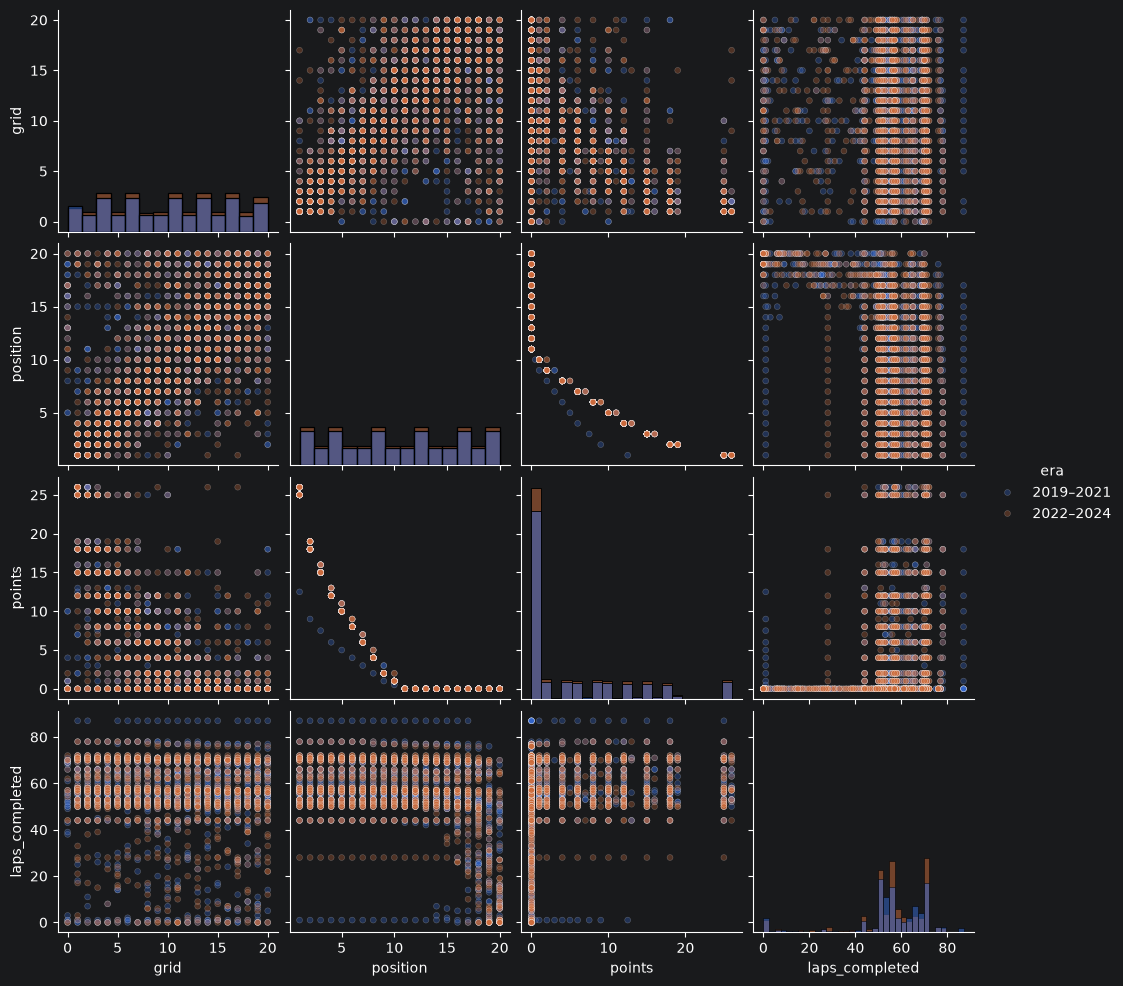

In [118]:
pair_data = analysis4[
    ["grid", "position", "points", "laps_completed", "era"]
].dropna()

sns.pairplot(
    data=pair_data,
    vars=["grid", "position", "points", "laps_completed"],
    hue="era",
    diag_kind="hist",
    plot_kws={"alpha": 0.3, "s": 18}
)

plt.show()

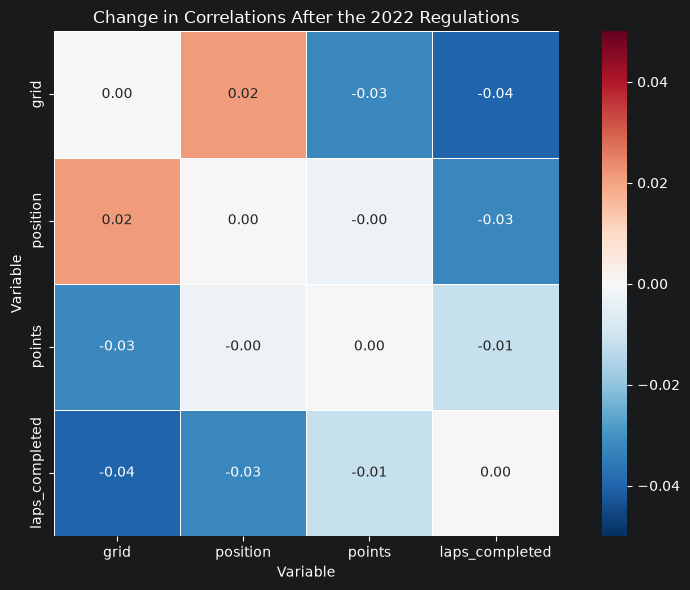

In [126]:
# The pair graph can be summarised with a correlation difference heatmap:
correlation_difference = (
    correlation_by_era["2022–2024"]
    - correlation_by_era["2019–2021"]
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_difference,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-0.05,
    vmax=0.05,
    square=True,
    linewidths=0.5
)

plt.title("Change in Correlations After the 2022 Regulations")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


#### Analysis 4: How Are Grid Position, Finishing Position, Points and Laps Completed Related?

The correlation matrices reveal several relationships between race performance variables, with only minor differences between the 2019–2021 and 2022–2024 periods.

Starting-grid position had a moderate positive correlation with finishing position (0.57 before 2022 and 0.59 afterwards), indicating that** drivers starting further back generally finished further back**. Its negative correlation with points also strengthened slightly, from −0.60 to −0.63, suggesting that starting further down the grid may have become marginally more costly in terms of points. However, these small changes could reflect differences in team performance and race circumstances rather than a change in the regulations' effects.

Finishing position had a moderately negative correlation with laps completed, which became slightly stronger after 2022 (−0.40 to −0.43). This may reflect retirements or race incidents, as drivers who complete fewer laps often cannot achieve a high finishing position. It raises the question of whether reliability or race incidents contributed to the pattern, although laps completed alone cannot distinguish between these explanations.

The strongest relationship was between finishing position and points (−0.85 in both periods). This is expected because points are largely awarded according to finishing position, so it offers limited insight into changes in racing behaviour. The relationship between points and laps completed also remained weak and positive (0.22 to 0.21).

Overall, finishing position was closely related to points, while starting position was moderately associated with both finishing position and points. The **relationships changed very little between the two eras**, suggesting that the broad patterns of race performance remained similar.

### 5. How did constructor performance change across 2019–2024?

In [134]:
# Keep GP race results
constructor_results = f1_results[
    f1_results["type"] == "R"
].copy()

# Check the constructors
print(constructor_results["team_name"].value_counts())


constructor_results[
    ["year", "name", "team_name", "position", "points"]
].head()


team_name
Mercedes          256
Red Bull          256
Ferrari           256
Haas F1 Team      256
McLaren           256
Williams          255
Alfa Romeo        208
Alpine F1 Team    180
Aston Martin      180
AlphaTauri        166
Renault            76
Racing Point       76
Sauber             48
RB F1 Team         48
Toro Rosso         42
Name: count, dtype: int64


,year,name,team_name,position,points
0,2019,Australian Grand Prix,Mercedes,1.0,26.0
4,2019,Australian Grand Prix,Mercedes,2.0,18.0
8,2019,Australian Grand Prix,Red Bull,3.0,15.0
12,2019,Australian Grand Prix,Ferrari,4.0,12.0
16,2019,Australian Grand Prix,Ferrari,5.0,10.0


In [137]:
# Some of the constructors rebranded over the years so historical names need to be mapped to modern names

constructor_mapping = {
    "Sauber": "Sauber / Alfa Romeo",
    "Alfa Romeo": "Sauber / Alfa Romeo",

    "Toro Rosso": "Toro Rosso / AlphaTauri / Racing Bulls",
    "AlphaTauri": "Toro Rosso / AlphaTauri / Racing Bulls",
    "RB F1 Team": "Toro Rosso / AlphaTauri / Racing Bulls",

    "Renault": "Renault / Alpine",
    "Alpine F1 Team": "Renault / Alpine",

    "Racing Point": "Racing Point / Aston Martin",
    "Aston Martin": "Racing Point / Aston Martin"
}

constructor_results["constructor"] = (
    constructor_results["team_name"]
    .replace(constructor_mapping)
)


constructor_results["constructor"].unique()


array(['Mercedes', 'Red Bull', 'Ferrari', 'Haas F1 Team',
       'Renault / Alpine', 'Sauber / Alfa Romeo',
       'Racing Point / Aston Martin',
       'Toro Rosso / AlphaTauri / Racing Bulls', 'McLaren', 'Williams'],
      dtype=object)

In [142]:

# Total points scored by each constructor in each season
constructor_points = (
    constructor_results
    .groupby(["year", "constructor"])["points"]
    .sum()
    .reset_index()
    .rename(columns={"points": "total_points"})
)

# Count the number of Grand Prix races in each season
races_per_year = (
    constructor_results[["year", "name"]]
    .drop_duplicates()
    .groupby("year")
    .size()
    .reset_index(name="race_count")
)

# Add race counts and calculate average points per race
constructor_points = constructor_points.merge(
    races_per_year,
    on="year",
    how="left"
)

constructor_points["points_per_race"] = (
    constructor_points["total_points"]
    / constructor_points["race_count"]
)

constructor_points.head()


,year,constructor,total_points,race_count,points_per_race
0,2019,Ferrari,504.0,21,24.000000
1,2019,Haas F1 Team,28.0,21,1.333333
2,2019,McLaren,145.0,21,6.904762
3,2019,Mercedes,739.0,21,35.190476
4,2019,Racing Point / Aston Martin,73.0,21,3.476190


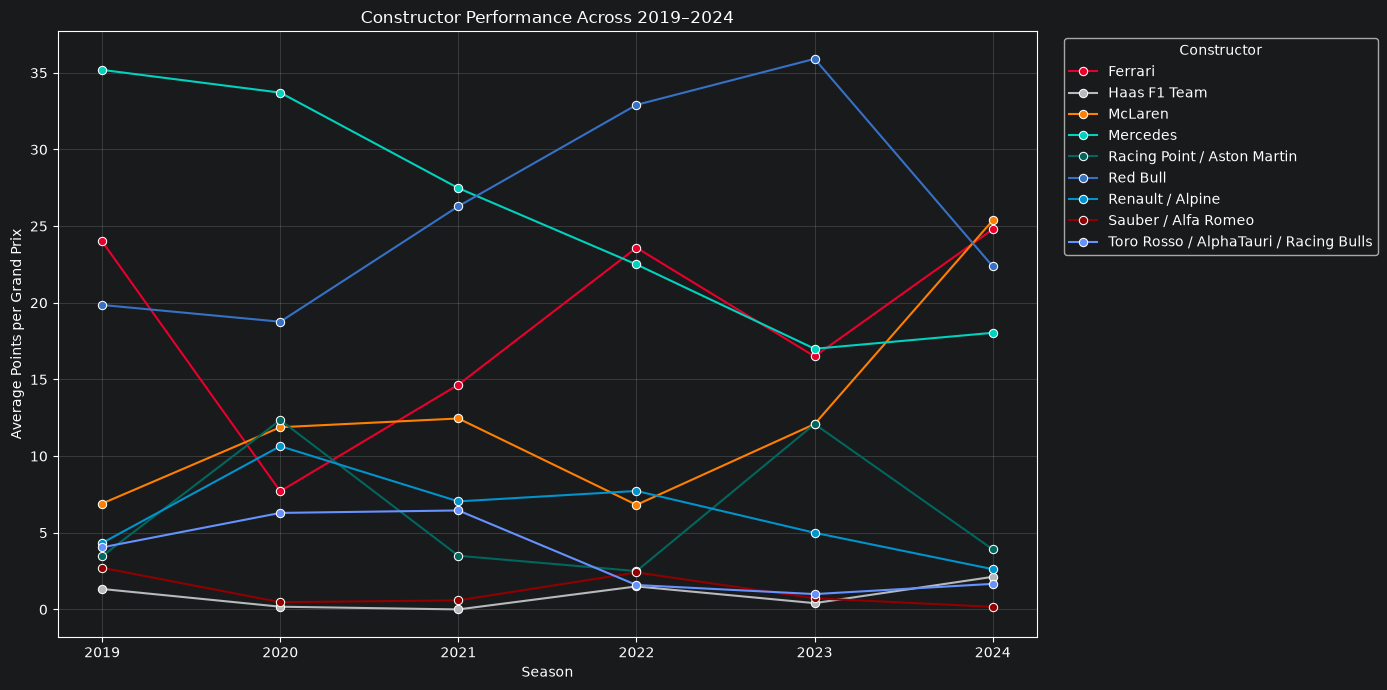

In [144]:
# Custom constructor colours
team_colours = {
    "Ferrari": "#E8002D", 
    "Haas F1 Team": "#B6BABD", 
    "McLaren": "#FF8000",
    "Mercedes": "#00D2BE",  
    "Racing Point / Aston Martin": "#00665E",
    "Red Bull": "#3671C6",  
    "Renault / Alpine": "#0093CC",  
    "Sauber / Alfa Romeo": "#900000",  
    "Toro Rosso / AlphaTauri / Racing Bulls": "#6692FF"  
}

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=constructor_points,
    x="year",
    y="points_per_race",
    hue="constructor",
    hue_order=list(team_colours.keys()),
    palette=team_colours,
    marker="o"
)

plt.title("Constructor Performance Across 2019–2024")
plt.xlabel("Season")
plt.ylabel("Average Points per Grand Prix")
plt.xticks(range(2019, 2025))
plt.grid(alpha=0.3)
plt.legend(
    title="Constructor",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()



#### Analysis 5: How Did Constructor Performance Change Across 2019–2024?

Constructor performance changed considerably between 2019 and 2024, with several teams rising or falling in the competitive order. Mercedes dominated the early part of the period, averaging 35.2 points per Grand Prix in 2019. However, its average fell to 22.5 in 2022 and 17.0 in 2023, suggesting that the introduction of the new aerodynamic regulations coincided with a loss of its earlier advantage. Red Bull moved in the opposite direction, increasing from 26.3 points per race in 2021 to 32.9 in 2022 and reaching 35.9 in 2023. This suggests that Red Bull adapted particularly well to the new regulations, although the figures alone cannot establish that the regulations caused the change.

The competitive order continued to evolve. Ferrari recovered from a difficult 2020 season, rising from 7.7 points per race that year to 23.6 in 2022. McLaren's improvement was particularly striking later in the period: its average increased from 6.8 points per race in 2022 to 25.4 in 2024, overtaking both Red Bull and Mercedes on this measure. In contrast, Aston Martin's strong 2023 performance, averaging 12.1 points per race, fell to 3.9 in 2024. These shifts show that performance under a new set of regulations was not fixed, with teams experiencing different development trajectories over time.

The gap between the leading constructors also appears to have narrowed towards the end of the period, suggesting a more competitive fight at the front of the grid. In 2023, Red Bull averaged 35.9 points per Grand Prix, well ahead of McLaren at 12.1 and Mercedes at 17.0. By 2024, McLaren had risen sharply to 25.4 points per race, compared with 24.8 for Ferrari, 22.4 for Red Bull and 18.0 for Mercedes. This convergence suggests that the leading teams were more closely matched by 2024, rather than Red Bull maintaining the same advantage it had established in 2023.

Overall, the data shows a changing competitive landscape rather than one team maintaining a consistent advantage. Red Bull initially established a strong lead under the new regulations, but McLaren's later improvement suggests that the balance of performance continued to shift.

# Final Summary

## 1. Introduction

This project investigated Formula 1 race performance between 2019 and 2024, focusing on whether the relationships between starting position, finishing position, points and constructor performance changed following the introduction of the new technical regulations in 2022.

The six-season period provides an opportunity to compare three seasons before the regulation change with three seasons afterwards.

The analysis covered five main areas:

1. The relationship between starting grid position and finishing position.
2. The likelihood of achieving a podium from different grid positions.
3. Changes in positions gained or lost during races.
4. Relationships between grid position, finishing position, points and laps completed.
5. Changes in constructor performance throughout the six seasons.

The overall findings suggest that the fundamental relationship between starting position and race results remained relatively stable, while the competitive order between constructors changed considerably. The data also indicates that McLaren's strong improvement by 2024 coincided with a closer contest among the leading teams.

## 2. Key Findings

### 2.1 Starting position remained an important predictor of finishing position

The first analysis found a moderate positive correlation between grid position and finishing position in both periods:

- 2019–2021: 0.672
- 2022–2024: 0.686

Because a larger numerical grid position means starting further back, the positive correlation indicates that drivers starting further down the grid generally also finished further down the order.

The correlation increased only slightly after 2022. This suggests that the relationship between starting position and finishing result remained broadly consistent despite the change in technical regulations.

The mean absolute change in finishing position was also almost identical: approximately 3.12 places before 2022 and 3.11 afterwards. The median change was two places in both periods.

Key finding: Starting position continued to be an important indicator of likely race outcome, with little evidence of a major change between the two periods.

### 2.2 Starting near the front remained advantageous for podium finishes

The podium analysis showed that drivers starting near the front of the grid generally had a much higher probability of finishing in the top three.

Pole position produced a podium finish in approximately 85.7% of classified results in 2019–2021 and 87.1% in 2022–2024. Grid position two also produced consistently high podium rates, at 75.4% and 73.8%, respectively.

This reinforces the findings from the first analysis: a strong starting position was associated with a better finishing result in both periods.

However, not every grid position followed the same pattern. Grid position three had a podium rate of 71.7% before 2022, falling to 47.6% afterwards. Meanwhile, grid position five increased from 14.8% to 26.2%.

These differences suggest that individual grid positions did not necessarily benefit equally across the two periods. However, the figures alone cannot explain why these changes occurred. They could reflect differences in the drivers, constructors, circuits or race circumstances represented in each period.

Key finding: Starting near the front remained advantageous, but the size of the advantage varied by grid position and season.

### 2.3 Drivers gained slightly more positions after 2022, but the difference was small

The third analysis examined positions gained or lost, calculated by subtracting finishing position from starting grid position.

A positive value indicates that a driver finished ahead of their starting position, while a negative value indicates that they lost places.

| Measure                 | 2019–2021 | 2022–2024 |
| ----------------------- | --------- | --------- |
| Mean positions gained   | 0.58      | 0.72      |
| Median positions gained | 1         | 1         |
| Standard deviation      | 4.51      | 4.40      |

The mean increased from 0.58 to 0.72 positions gained per classified result. This represents a small increase of 0.14 places. However, the median remained unchanged, while the standard deviation decreased slightly.

This means that the typical classified result did not change substantially. The difference in the mean could instead reflect a small shift in the overall distribution, potentially influenced by particular drivers, teams or races.

The analysis therefore does not provide strong evidence that drivers generally gained substantially more positions under the new regulations.

Key finding: Position changes remained broadly similar across the two periods, with only a small increase in the average number of places gained.

### 2.4 The relationships between race variables changed very little

The fourth analysis compared correlations between grid position, finishing position, points and laps completed.

The strongest relationship was between finishing position and points, with a correlation of approximately -0.85 in both periods. This is expected because points are largely awarded according to finishing position: lower numerical finishing positions generally correspond to higher points totals.

Grid position had a moderate positive correlation with finishing position, increasing from 0.57 to 0.59. Its correlation with points became slightly more negative, moving from -0.60 to -0.63.

The relationship between finishing position and laps completed also became slightly more negative, changing from -0.40 to -0.43. One possible explanation is that retirements or incidents can prevent drivers from completing the race distance and achieving a high finishing position. However, these correlations cannot distinguish between mechanical failures, collisions, strategic retirements and other causes.

Overall, the differences between the two correlation matrices were small. This suggests that the broad relationships between race performance variables remained stable across the regulation change.

Key finding: The data revealed consistent relationships between starting position, finishing position and points, with only minor changes in their strength after 2022.

### 2.5 Constructor performance changed considerably

In contrast to the relatively stable driver-level relationships, the constructor analysis revealed substantial changes in the competitive order.

Mercedes was particularly strong at the beginning of the period, averaging 35.2 points per Grand Prix in 2019. Its average subsequently declined, reaching 22.5 in 2022 and 17.0 in 2023.

Red Bull moved in the opposite direction. Its average increased from 26.3 points per Grand Prix in 2021 to 32.9 in 2022, before reaching 35.9 in 2023.

Ferrari also recovered from a difficult 2020 season, increasing from 7.7 points per Grand Prix that year to 23.6 in 2022.

McLaren's development was particularly striking towards the end of the period. Its average increased from 6.8 points per Grand Prix in 2022 to 12.1 in 2023 and 25.4 in 2024.

Meanwhile, Aston Martin's average increased to 12.1 in 2023 before falling to 3.9 in 2024.

These changes demonstrate that constructor performance was not fixed following the introduction of the 2022 regulations. Teams experienced different development trajectories, with some losing ground while others made substantial improvements.

Key finding: Constructor performance was much more dynamic than the broad statistical relationships between individual race variables.

## 3. Major Trends Across 2019–2024

### 3.1 The competitive order shifted after 2022

The introduction of the 2022 technical regulations coincided with a change in the relative performance of several leading constructors.

Mercedes' decline from its earlier peak contrasted with Red Bull's rise to the front of the field. Ferrari also became more competitive in 2022, while McLaren's most significant improvement came later.

This indicates that the transition to the new regulations was followed by different outcomes for different teams. Some initially established a stronger position, while others required more time to become competitive.

However, the analysis cannot establish that the regulations alone caused these changes. Team development, driver performance, reliability, upgrades and race-specific circumstances may also have contributed.

### 3.2 The gap between the leading constructors narrowed by 2024

One of the most notable trends was the convergence in points per Grand Prix among the leading constructors in 2024.

| Constructor | 2023 points per Grand Prix | 2024 points per Grand Prix |
| ----------- | -------------------------- | -------------------------- |
| Red Bull    | 35.9                       | 22.4                       |
| McLaren     | 12.1                       | 25.4                       |
| Ferrari     | 16.5                       | 24.8                       |
| Mercedes    | 17.0                       | 18.0                       |

Figures are calculated from Grand Prix race results only; sprint points are excluded.

In 2023, Red Bull had a substantial advantage, averaging 35.9 points per Grand Prix. By 2024, McLaren, Ferrari and Red Bull were much closer together on this measure, with averages between approximately 22 and 25 points.

McLaren's rise was particularly important. Its average more than doubled between 2023 and 2024, while Red Bull's fell substantially. Ferrari also recorded a strong average in 2024.

This suggests that the leading constructors became more closely matched in their race results, making the contest at the front more competitive. Rather than one team maintaining a consistent advantage, the balance shifted as teams developed their cars.

It is important to distinguish this from saying that every race became more competitive. Seasonal averages show the overall trend but do not directly measure the closeness of individual race finishes or the frequency of on-track battles.

### 3.3 McLaren's improvement was one of the clearest developments

McLaren's progression from 6.8 points per Grand Prix in 2022 to 25.4 in 2024 was one of the largest positive changes in the constructor analysis.

This suggests a substantial improvement in its ability to achieve strong race results over the period. By 2024, its average was slightly higher than Ferrari's and Red Bull's.

The trend also illustrates why comparing only the first season after a regulation change can be misleading. A team's initial performance does not necessarily reflect where it will stand after several seasons of development.

### 3.4 Strong starting positions continued to matter despite the changing competitive order

Although constructor performance changed significantly, the relationship between starting grid and finishing position remained similar.

This is an important distinction: the teams competing for the strongest results changed, but the overall association between starting near the front and finishing near the front did not change substantially.

The findings therefore suggest that the competitive order can evolve considerably without fundamentally changing the relationship between qualifying position and race outcome.

## 4. Unexpected Results and Interesting Observations

### 4.1 The new regulations did not produce a clear increase in position changes

A possible expectation was that the new regulations might substantially alter how drivers could overtake and move through the field.

However, the mean absolute change in finishing position remained almost identical between the two periods, and the median was unchanged. The average number of positions gained increased by only 0.14 places among classified results.

This was a useful finding because it challenged the idea that a major technical change must necessarily produce a large, easily measurable change in race-position movement.

It does not mean the regulations had no effect on overtaking. Position changes are influenced by many factors, and these metrics do not directly measure overtaking opportunities, attempts or successful passes.

### 4.2 Grid position three experienced a notable fall in podium rate

The podium rate for grid position three declined from 71.7% before 2022 to 47.6% afterwards, despite pole position remaining relatively stable.

This difference stands out because grid positions three and four are close together on the starting grid, yet the observed outcomes can differ considerably.

An interesting follow-up would be to investigate whether this result was concentrated among particular constructors or drivers, or whether it was influenced by the circuits and seasons included in each group. The sample size and variation between individual seasons should also be considered before drawing strong conclusions.

### 4.3 McLaren's rise and Red Bull's decline happened at the same time

The constructor analysis showed a striking change between 2023 and 2024: McLaren's average points increased sharply while Red Bull's fell.

This is more informative than simply identifying the strongest constructor in each season. It highlights how the competitive balance evolved over time and how quickly the relative performance of leading teams can change.

However, the analysis measures points rather than underlying car performance. Points can be influenced by driver results, reliability, incidents, strategy and other factors, so the trend should be interpreted as a change in competitive outcomes rather than a direct measurement of car speed.

### 4.4 Some relationships were strong but offered limited new insight

The correlation between finishing position and points was consistently strong at approximately -0.85. Although this confirms an expected relationship, it offers limited evidence about changes in racing behaviour because the points system itself links points closely to finishing position.

This highlights an important lesson from the analysis: a strong correlation is not automatically a surprising or useful discovery. The value of a statistical result depends on whether it helps answer the research question.

By comparison, the changes in constructor performance and the convergence among leading teams in 2024 provided more distinctive insights into how the sport evolved during the period.

## 5. What Do the Findings Suggest About the 2022 Regulations?

Taken together, the results present a mixed picture.

At the driver and race-result level, the statistical relationships changed relatively little. Starting grid position remained moderately associated with finishing position, podium chances remained highest for drivers starting near the front, and the average movement in finishing positions was broadly stable.

At the constructor level, however, the competitive order changed considerably. Red Bull strengthened its position after 2021, Mercedes lost some of its earlier advantage, Ferrari recovered, and McLaren made a substantial improvement by 2024.

These findings suggest that the most visible change in this dataset was the evolution of the competitive order, rather than a fundamental change in the relationship between starting position and race outcome.

Nevertheless, the analysis cannot isolate the effect of the regulations from other influences. The comparison divides the dataset into two periods, but it does not control for differences in drivers, teams, circuits, race incidents or other conditions. It therefore identifies patterns associated with the two periods rather than proving that the regulations caused them.

A more detailed investigation could examine overtaking statistics, qualifying-to-race position changes by constructor, safety-car periods, retirements and race-level performance. These would help establish whether the observed trends were accompanied by changes in the way races were contested.

## 6. Limitations of the Analysis

Several limitations should be acknowledged when interpreting the findings.

### 6.1 The analysis is based on correlations and descriptive statistics

Correlation identifies the strength and direction of relationships between variables, but it does not establish causation. For example, the relationship between grid and finishing position does not prove that starting position alone determined the result.

Similarly, the observed changes after 2022 cannot be attributed exclusively to the technical regulations.

### 6.2 Unclassified results were excluded from some analyses

The starting-position, podium-rate and positions-gained analyses used classified results. This helps make comparisons more consistent, but it excludes some races in which drivers retired or failed to be classified.

As a result, the findings describe position changes and podium outcomes among classified results, rather than every race entry. This may underrepresent some of the effects of reliability problems and race incidents.

The correlation analysis included all race entries, including unclassified results, which means its population differs from the classified-results analyses.

### 6.3 Constructor names had to be consolidated across seasons

Several constructors changed names during the period. For example, the analysis grouped Sauber with Alfa Romeo, Renault with Alpine, and Racing Point with Aston Martin. It also grouped Toro Rosso, AlphaTauri and RB F1 Team into one lineage.

This makes it easier to follow longer-term performance trends, but it also means the analysis follows constructor lineages rather than treating every historical name as an entirely separate entry. It should not be interpreted as evidence that the team, ownership, personnel or technical approach remained identical throughout each lineage.

### 6.4 Constructor points exclude sprint races

The constructor comparison uses points awarded in Grand Prix race sessions and excludes sprint-race points. Consequently, these figures are not the same as official championship totals for seasons that included sprint races.

Points per Grand Prix are still useful for comparing the race results included in this dataset, but the exclusion should be considered when interpreting differences between seasons.

### 6.5 The periods contain different numbers of race entries

The two periods include different numbers of race entries and races. Some constructors also have slightly different numbers of entries, such as Williams in 2024.

Using points per Grand Prix helps account for differences in the number of races, but it does not control for every difference between seasons. The average can still be influenced by the particular races, drivers and circumstances represented in each period.

### 6.6 The analysis covers only six seasons

The dataset provides a useful comparison before and after the 2022 regulation change, but six seasons are not enough to establish a universal pattern. Additional seasons could reveal whether the 2024 convergence among leading constructors continued or was temporary.

## 7. Further Analysis and Possible Improvements

The current analysis provides a foundation for several extensions.

- Investigate podium-rate changes: Explore why grid position three had a lower podium rate after 2022, separating the results by constructor, driver or season.
- Compare qualifying and race performance by constructor: Examine whether particular teams were more likely to finish ahead of or behind their starting positions after 2022.
- Examine retirements and reliability: Investigate whether the relationship between laps completed and finishing position is associated with retirements, mechanical failures or race incidents.
- Use official championship points for a separate comparison: Include sprint points where applicable if the aim is to compare each constructor's full-season championship performance.
- Analyse individual race competitiveness: Compare winning margins, gaps between the top finishers or the number of different race winners to investigate whether the races themselves became more competitive.
- Extend the time period: Add later seasons to determine whether the convergence among leading constructors persisted beyond 2024.

These extensions would help move the project from identifying broad patterns towards investigating the possible explanations behind them.

## 8. Conclusion

The results show that starting position remained an important indicator of finishing position and podium success. The relationships between grid position, finishing position, points and laps completed also remained broadly stable. Drivers gained slightly more positions on average after 2022, but the difference was small and the median remained unchanged.

The most substantial changes appeared in constructor performance. Mercedes' earlier advantage diminished, Red Bull became the leading constructor in 2022 and 2023, Ferrari recovered, and McLaren made a major improvement by 2024. By the final season, the points-per-Grand-Prix averages of Red Bull, McLaren and Ferrari had converged, suggesting a closer contest among the leading constructors.

The analysis therefore highlights a distinction between stable relationships within race results and substantial changes in which teams were most successful. The new regulations coincided with a changing competitive order, but the data does not establish that the regulations alone caused these developments.